## 1. 합성곱 신경망 (CNN)

### 1-0. 픽셀과 채널

> **핵심** 이미지는 픽셀 값이 모인 숫자 데이터이고, 색을 몇 개의 값으로 표현하느냐에 따라 채널 수가 정해짐

**픽셀**은 이미지를 이루는 가장 작은 단위로, 특정 위치의 색상이나 밝기 정보를 숫자로 담고 있음. 
흑백 이미지는 (세로 픽셀 수 × 가로 픽셀 수)의 2차원 배열, 예를 들어 28 × 28 이미지는 세로 가로 각각 28개의 픽셀로 이루어진 것임. 흑백 이미지는 픽셀 하나에 0~255 사이의 밝기 값 하나만 가지는데, 0은 검은색, 255는 흰색이고 그 사이는 회색 단계임. 컬러(RGB) 이미지는 픽셀 하나를 빨강, 초록, 파랑 세 값의 조합으로 표현함.

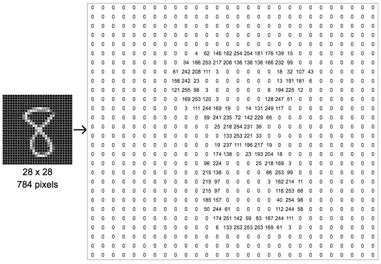

**채널**은 이미지의 색상 정보를 나눠 저장하는 데이터 층을 말하고, **색공간**은 색을 숫자로 표현하는 체계를 말함. 대표적인 색공간은 밑에 세 가지
- **그레이 스케일**: 색 구분 없이 밝기만으로 표현함. 저장할 정보가 밝기 하나뿐이라 채널 수가 1이고, (28 × 28 × 1) 텐서로 표현하거나 NumPy에서는 채널을 생략해 (28 × 28)로 저장하기도 함
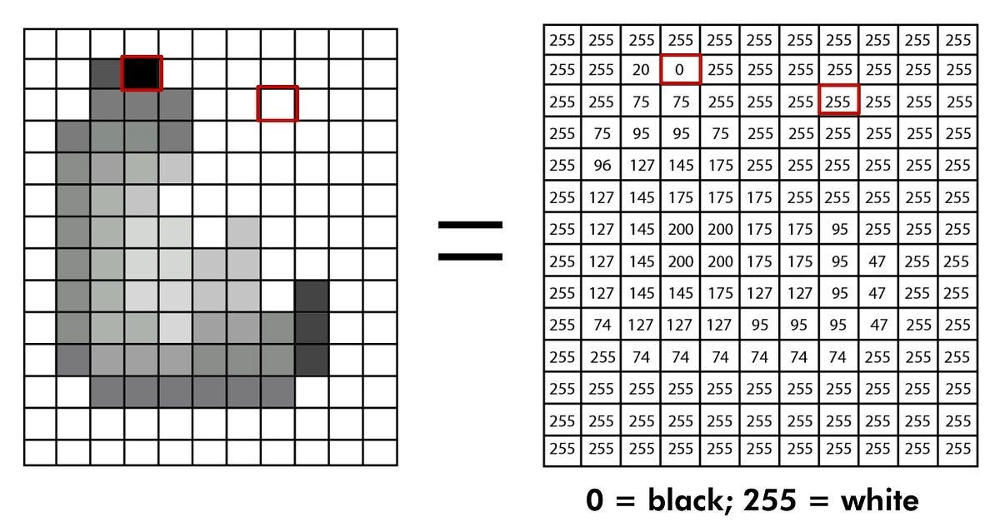
- **RGB**: 세 가지 색의 조합으로 표현함. 빨강과 초록이 높고 파랑이 낮으면 노란색 계열이 되는 식이며, 세 값이 합쳐져 하나의 색을 만들므로 채널 수는 3임. 28 × 28 컬러 이미지는 (28 × 28 × 3) 텐서가 되고, 채널은 깊이라고도 부름
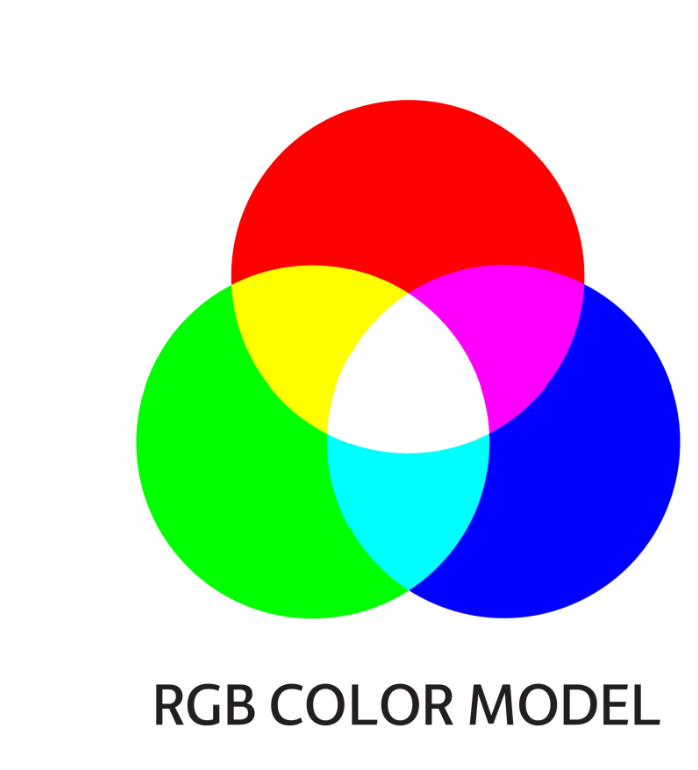
- **HSV**: 색상, 채도, 명도를 기준으로 표현
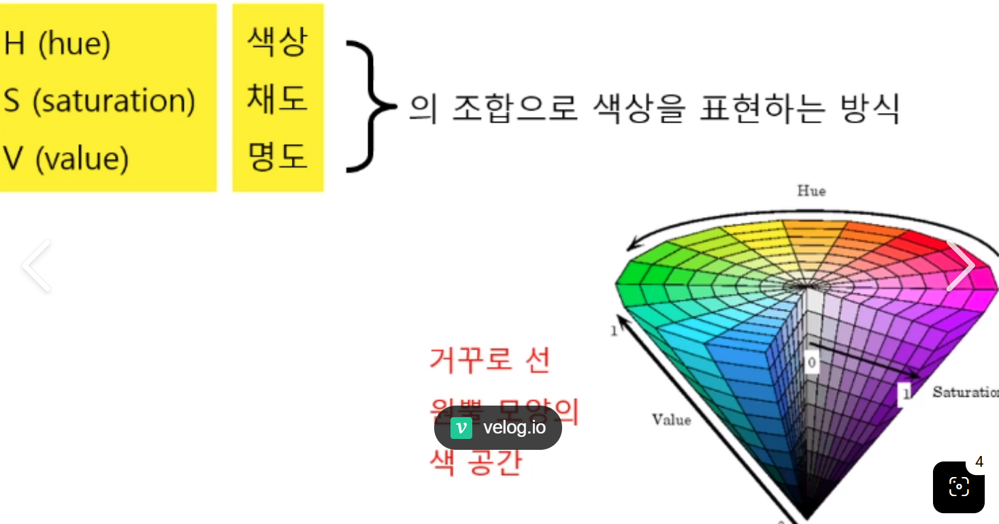


여기서 **텐서**라는 건 스칼라, 벡터, 행렬을 모두 포함하는 다차원 배열을 통칭하는 말임. 축 개수에 따라 0차원 1차원 2차원 3차원이상으로 나뉨

---

### 1-1. CNN의 개념

> **핵심** CNN은 이미지를 바로 펼치지 않고 Conv와 Pool로 공간적 특징을 먼저 뽑은 뒤 FC Layer로 분류하는 모델

**이미지 인식 방식의 차이**
사람은 강아지 사진을 볼 때 모든 픽셀을 하나하나 보지 않고, 눈·귀·코·꼬리처럼 구분에 중요한 부분에 집중한 뒤 이 특징들과 그 관계를 종합해 판단하지만 컴퓨터는 이미지를 사람처럼 이해하지 못하고 작은 픽셀 단위로 나눠 각 픽셀의 숫자를 처리하므로, 컴퓨터에게 이미지는 강아지 사진이 아니라 **수많은 픽셀 값의 모음**임.
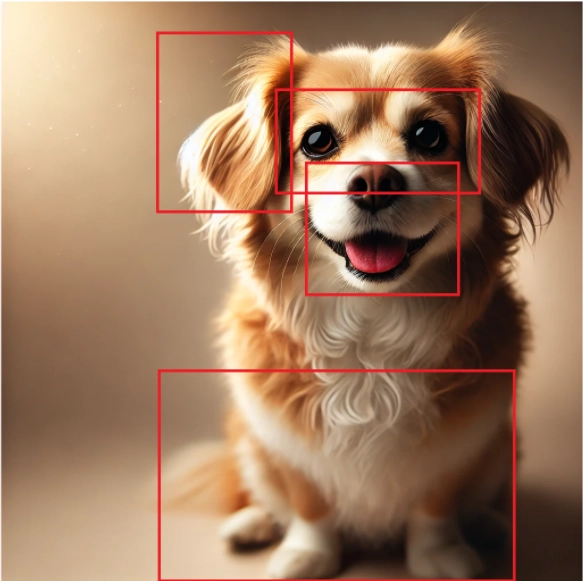 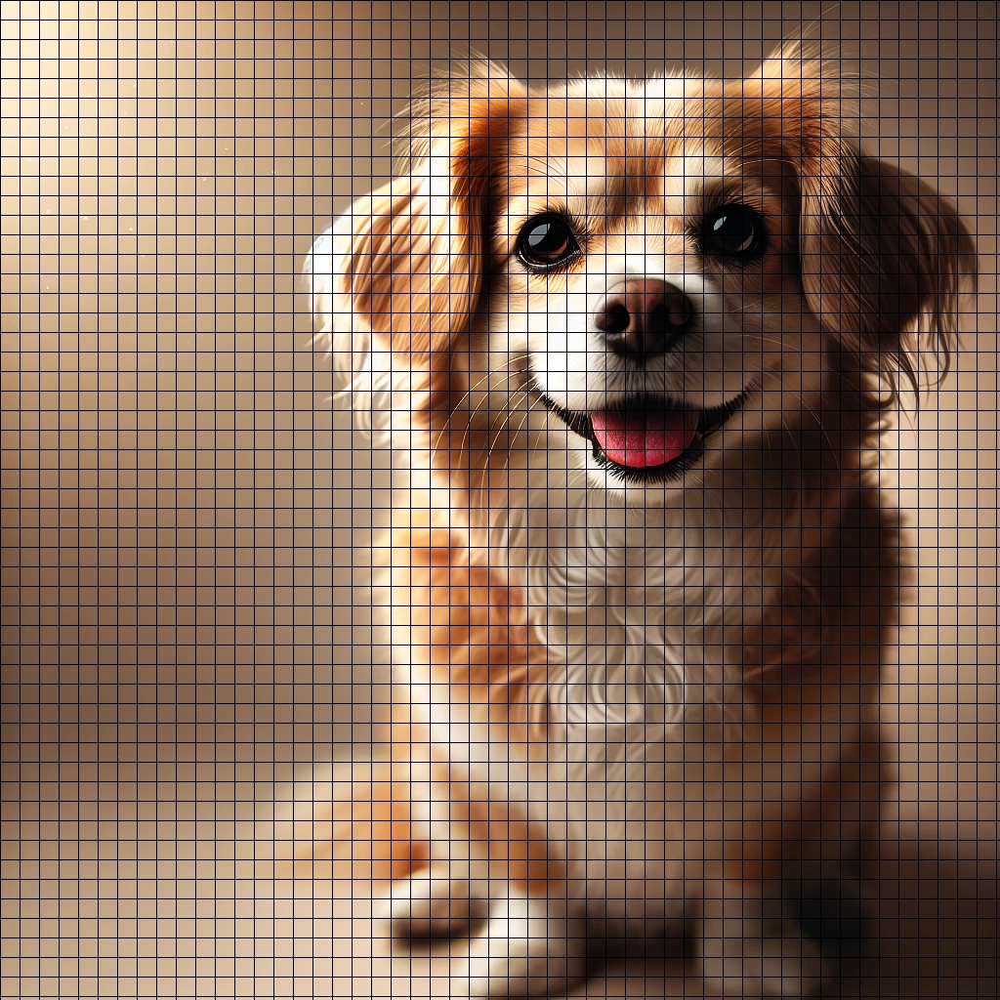

문제는 이 픽셀 정보를 1차원으로 펼쳐서 그대로 학습할 때 생김. 픽셀 순서가 뒤섞이는 건 아니지만, 서로 가까운 픽셀끼리 어떤 관계인지가 모델에 직접 반영되지 않아서, 주변 픽셀이 모여 만들어지는 눈이나 귀 같은 특징을 학습하기 어려워진다.

**MLP와 CNN의 구조 비교**
- MLP는 `FC Layer + … + FC Layer` 구조로, 이미지를 넣을 때 2차원 이미지를 1차원으로 펼쳐서 사용함
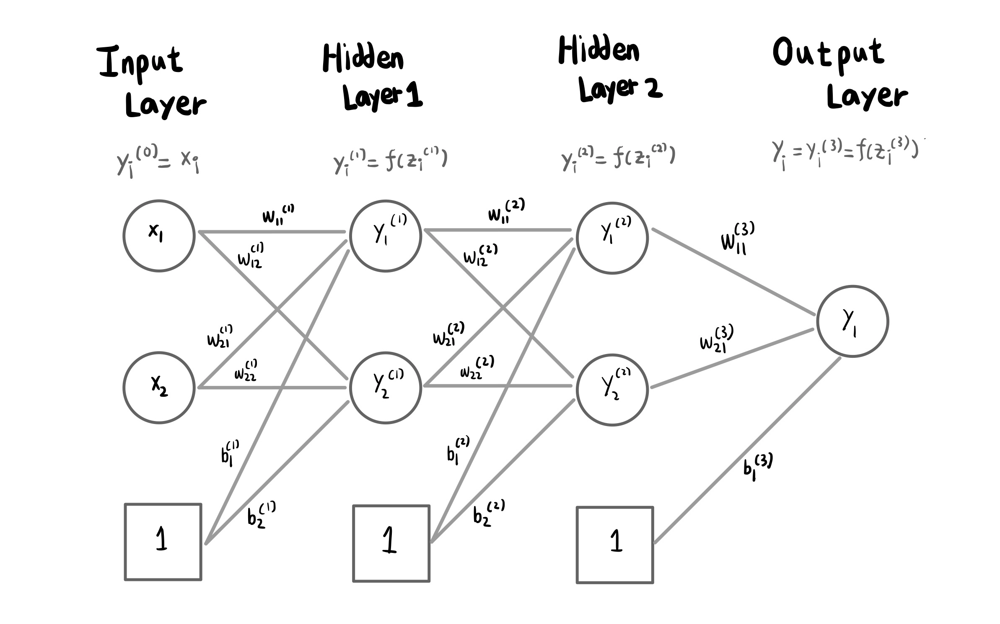
- CNN은 `(Conv + Pool) + … + Flatten + FC Layer + … + FC Layer` 구조로, 공간적 특징을 유지한 채 Conv와 Pool을 반복해 특징을 뽑고, 그 뒤에 Flatten으로 펼쳐 FC Layer에서 분류함

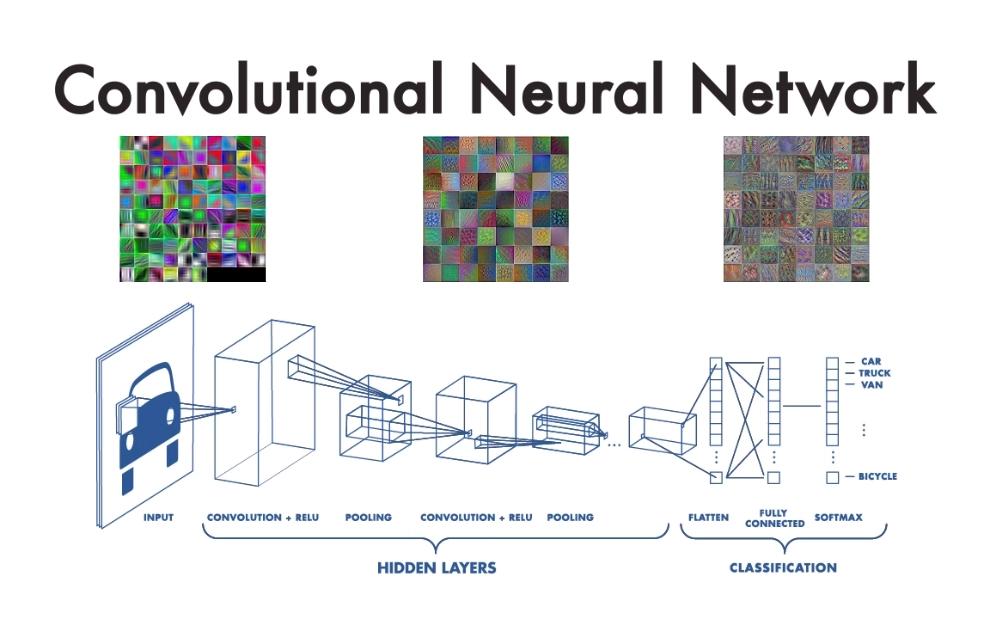

즉 두 모델의 가장 큰 차이는 **FC Layer 전에 Conv와 Pool로 특징을 학습하는 과정이 추가되었는지**임.

**CNN의 전체 구조**
CNN은 크게 특징을 학습하는 부분과 분류하는 부분으로 나뉨.
- **특징 추출(Feature Learning)**: Convolution Layer가 필터를 이미지 위에서 움직이며 모서리, 질감, 형태 같은 특징을 뽑고, Pooling Layer가 그 결과의 크기를 줄이면서 중요한 특징은 남겨 연산량을 줄임
- **Flatten**: 여러 차원의 특징 맵을 FC Layer에 넣을 수 있도록 1차원으로 바꿈
- **분류(Classification)**: Fully Connected Layer가 추출된 특징을 종합해 최종 클래스를 결정함

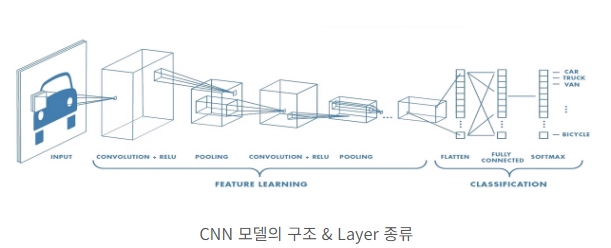

분류 부분은 기존에 배운 회귀·분류 모델과 비슷한 방식이고, CNN에서 새롭게 추가된 핵심은 특징 학습 부분이다.

---

### 1-2. WHY 이미지 처리에 MLP가 아닌 CNN을 쓸까?

> **핵심** MLP는 위치 변화에 약하고, 파라미터가 폭발적으로 늘며, 공간 정보를 잃는다는 한계가 있고 CNN은 이 세 가지를 모두 보완함

**이미지 데이터의 구조**
- 흑백: 픽셀마다 밝기 값 1개(0~255) → H × W 2차원 배열
- 컬러: 픽셀마다 색상 값 3개 → H × W × 3 3차원 배열
- 정형 데이터는 열마다 의미가 독립적이지만 이미지는 **주변 픽셀과의 관계, 위치 정보**가 중요함
- 그래서 구조를 유지한 채 학습하는 모델이 필요함 → CNN

**위치·크기·회전 변화에 취약함**
- MLP는 픽셀 위치마다 가중치를 학습함 → 숫자 1이 조금만 옆으로 가도 입력이 완전히 달라짐
- 학습 때 못 본 위치나 형태가 들어오면 같은 숫자로 인식을 못 함
- CNN은 같은 필터를 여러 위치에 반복 적용 + Pooling으로 작은 위치 변화를 흡수함
- 즉 "어느 픽셀에 있는지"가 아니라 **"그 특징이 있는지"** 를 학습함
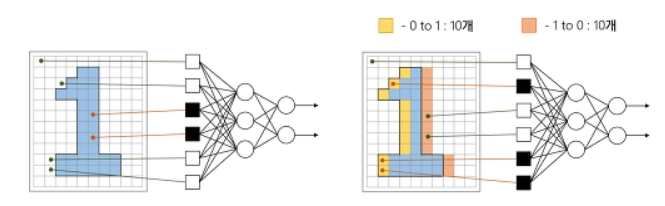

**파라미터 폭발**
- MLP는 모든 노드가 다음 층 모든 노드와 연결되는 완전연결 구조임
- 1000 × 1000 이미지를 노드 10,000개에 연결하면 가중치가 약 100억 개 → 과적합 위험, 학습 느려짐
- CNN은 작은 영역만 보는 **부분 연결**(3 × 3 필터면 한 번에 9개 픽셀만!) + 가중치 **공유**
- 이미지가 커져도 필터 크기·개수가 같으면 파라미터가 크게 늘지 않음

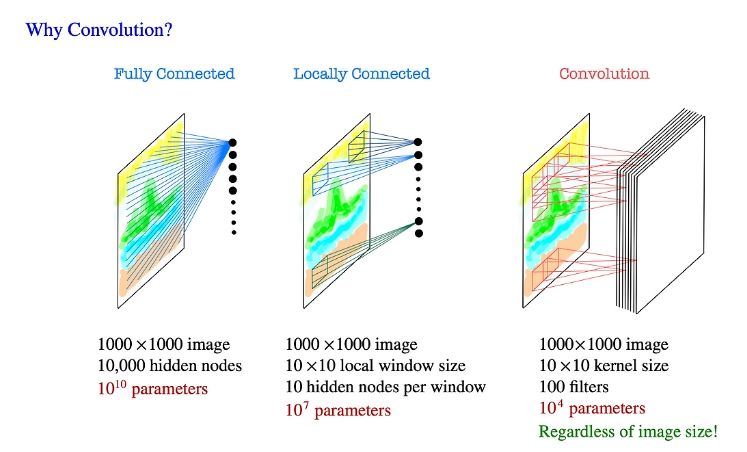

**공간 정보 손실**
- MLP는 처음부터 1차원으로 펼침 (28 × 28 → 784개)
- 값은 남아 있지만 어떤 픽셀끼리 붙어 있었는지는 사라짐
- MLP는 바로 Flatten, CNN은 **공간 특징을 먼저 학습한 뒤** Flatten
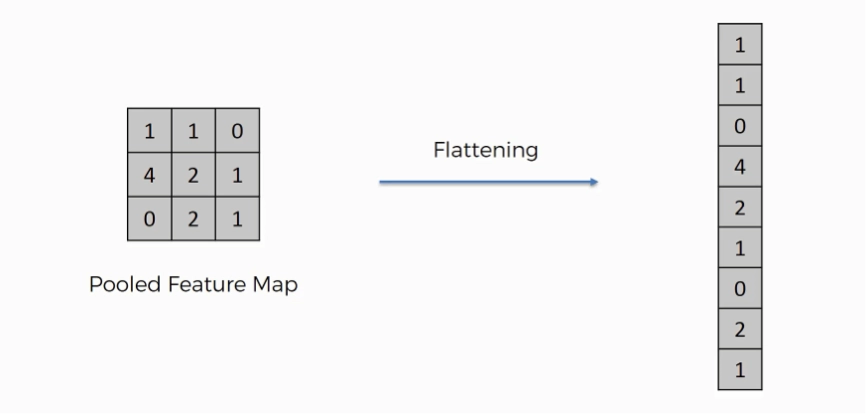

---

### 1-3. 합성곱과 풀링

> **핵심** Convolution과 Pooling이 특징 추출을 담당하고, Padding과 Stride는 출력 크기와 정보 보존 정도를 조절하는 하이퍼파라미터임

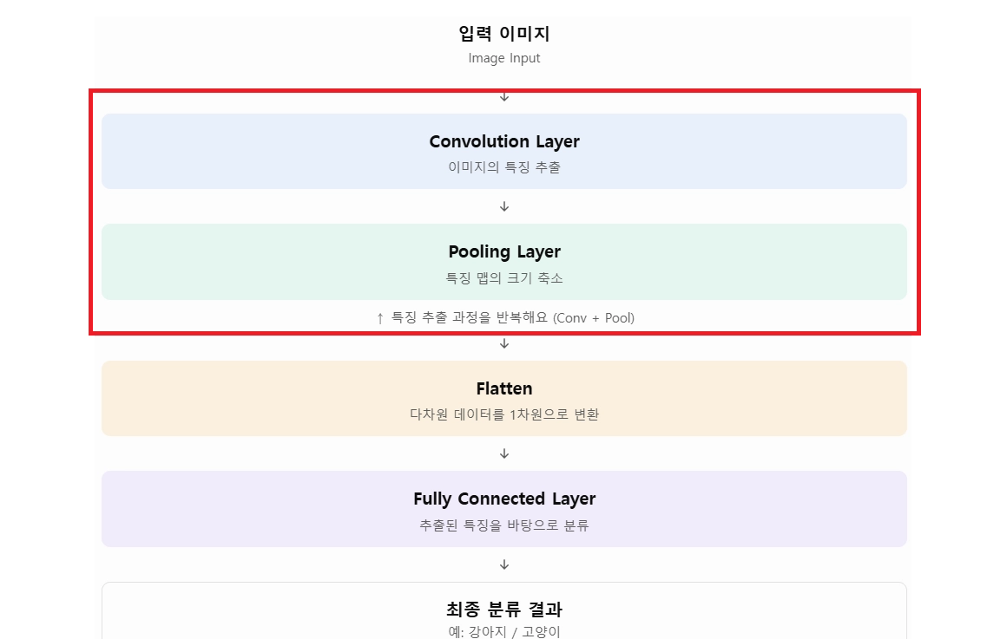

**Convolution Layer**
- 필터로 이미지를 훑으면서 수직선, 수평선, 모서리, 질감 같은 패턴을 찾는 층
- 연산 순서
  1. 필터를 왼쪽 위부터 오른쪽으로 옮기고, 한 줄 끝나면 다음 줄로
  2. 덮은 픽셀과 필터 가중치를 같은 위치끼리 곱해서 전부 더함 → 숫자 하나
  3. 그 값을 Feature Map에 저장 → 다 돌면 Feature Map 1개 완성

**Feature Map**
- Convolution의 결과물. 필터가 특징에 강하게 반응할수록 값이 커짐
- 개수 = 필터 개수 (3 × 5 × 5 필터 1개 → 1개, 6개 → 6개)
- 세로선 필터, 가로선 필터처럼 여러 필터로 서로 다른 특징을 뽑음

**Padding**
- 이미지 가장자리에 픽셀을 덧붙임 (보통 0으로 채우는 Zero Padding)
- 없으면 가장자리가 연산에 덜 들어감
- → 크기가 너무 줄어드는 걸 막고 **가장자리 특징까지 학습**하게 해 줌

**Stride 보폭**
- 필터가 한 번에 이동하는 칸 수
- 1이면 촘촘하게 봄 → 세부 특징에 유리, Feature Map 큼
- 2 이상이면 건너뛰며 봄 → Feature Map 작아지고 연산량 줄어듦
- → **세밀함과 연산 효율 사이를 조절**하는 값

**Pooling**
- 일정 영역(보통 2 × 2)의 값을 하나로 요약함
- 크기를 줄여 데이터 양을 줄이고, 작은 위치 변화에 덜 민감하게 만듦
- 없으면 필터가 딱 그 픽셀 위치에서만 패턴을 찾아서, 살짝만 움직여도 다른 특징으로 봄
- 종류: 가장 큰 값을 고르는 **Max Pooling**, 평균을 내는 **Average Pooling**
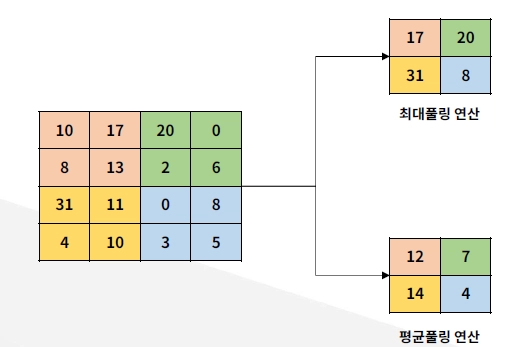
- 장점?: 크기를 줄여 계산량이 감소, 주변 값을 요약하므로 위치 변화에 강해지고 특정 위치에 지나치게 의존하는 것을 줄여 과적합 방지에 도움이 되고 강한 특징에 비해 작은 값이 덜 반영되어 노이즈 영향도 완화
- 단점?: 크기를 줄이는 과정에서 세부 정보가 사라질 수 있고, 객체 경계처럼 정확한 위치가 중요한 작업에서는 정보 손실이 문제가 될 수 있음
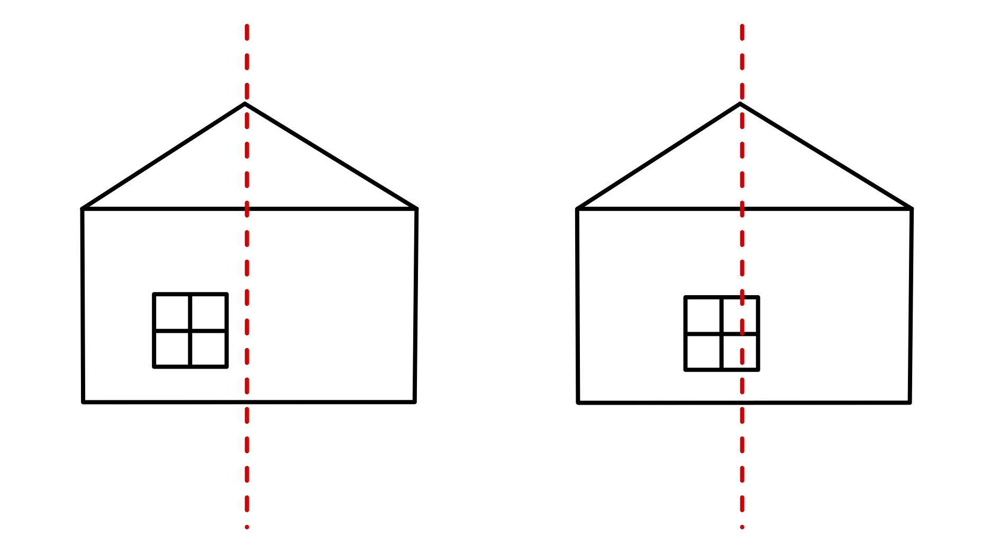


---

### 1-4. 대표적인 CNN 아키텍처들

> **핵심** AlexNet이 딥러닝의 가능성을 보여 줬다 /  VGGNet은 작은 필터로 깊게 쌓았다 / ResNet은 Skip Connection으로 매우 깊은 신경망의 학습을 가능하게 했다

**AlexNet (2012)**
2012년 ImageNet 대회에서 뛰어난 성과를 거두며 대규모 데이터로 특징을 직접 학습해 분류하는 딥러닝의 가능성을 보여 준 모델임. Convolution Layer 5개와 FC Layer 3개, 총 8개의 학습 계층으로 이루어지며 중간에 ReLU와 Max Pooling을 적용함. 딥러닝 발전에 기여한 기술은 다섯 가지임.
- **ReLU 도입**: 기존 Tanh 대신 ReLU를 써서 기울기 소실 문제를 해결하고 학습 속도를 6배 이상 높임
- **다중 GPU 병렬 연산**: 3GB짜리 GPU(GTX 580) 2개를 병렬로 연결해 네트워크를 상·하단으로 나눠 학습함
- **드롭아웃**: 과적합을 막기 위해 학습 중 FC 계층 뉴런 일부(예: 50%)를 무작위로 끔
- **데이터 증강**: 무작위 자르기, 좌우 반전, RGB 값 변경 등으로 학습 데이터를 인위적으로 늘림
- **로컬 응답 정규화(LRN)**: 강하게 활성화된 뉴런 주변을 감쇠시킴. 최근에는 배치 정규화로 주로 대체됨
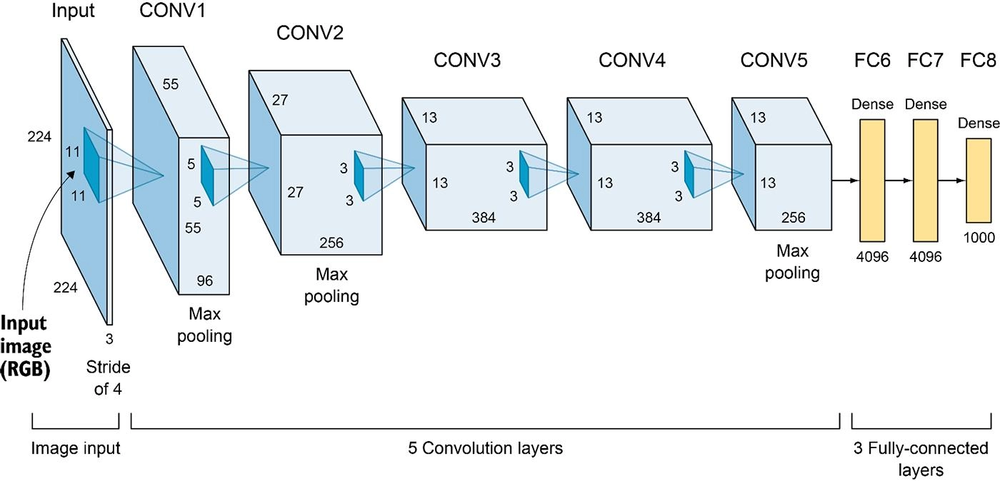

**VGGNet (2014)**
옥스퍼드대학교 연구팀이 만든 모델로, **네트워크를 깊게 쌓으면 성능이 좋아질 수 있음**을 보여 줌. VGG16, VGG19의 숫자는 학습 계층 수이며, VGG16은 Convolution Layer 13개와 FC Layer 3개로 구성됨. 대부분의 층에서 3 × 3의 작은 필터를 반복 사용하고 중간중간 Max Pooling을 넣어 구조가 일관되고 이해하기 쉬움. 비교적 큰 필터와 적은 층을 쓴 AlexNet과 달리, 작은 필터를 반복해 더 깊게 쌓음으로써 단순한 특징부터 복잡한 형태까지 더 세밀하게 학습할 수 있게 됨.
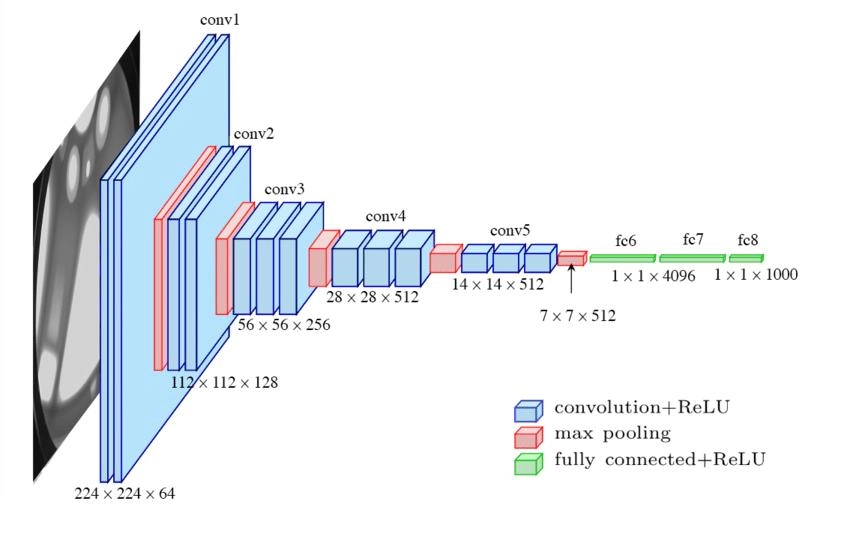

**ResNet (2015)**
깊은 신경망을 효과적으로 학습하기 위해 만든 모델로, 단순히 층을 이어 붙이던 방식에서 벗어나 **잔차 연결** 을 도입. 여러 Convolution Layer 사이에 Skip Connection을 두어 입력 정보가 중간 계층을 거치지 않고 뒤쪽으로 바로 전달되게 하고, 계층을 통과한 결과와 처음 입력을 더해 다음 층으로 넘김.
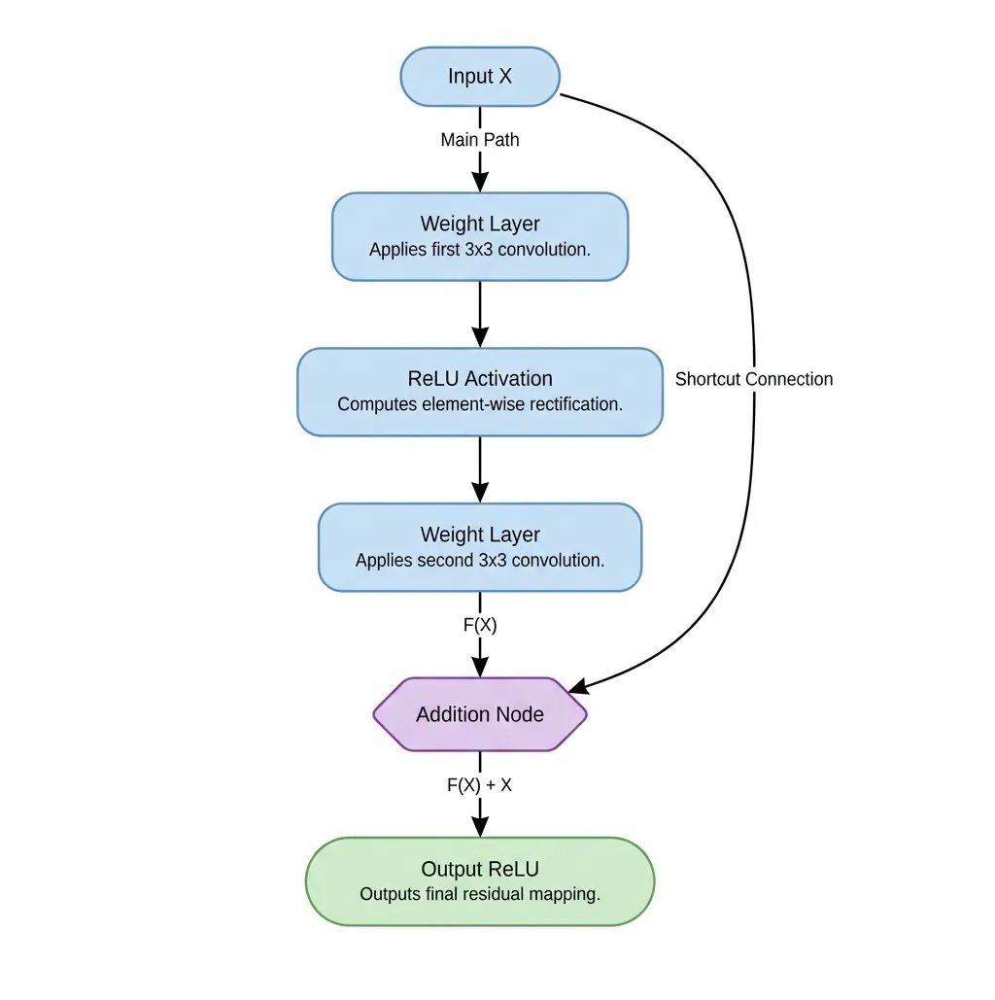

---

## 2. 이미지 딥러닝 응용

### 2-1. 이미지 분류 

> **핵심** 이미지 분류는 픽셀 값을 입력받아 미리 정한 클래스 중 하나로 분류하는 작업이고 모델마다 쓰임새와 주의점이 다름

- **AlexNet**은 구조가 비교적 단순한 초기 CNN이라 작은 데이터셋이나 개념 설명용으로 적절
- **VGG**는 더 깊은 구조라 계산량과 메모리 요구가 높음
- **ResNet**은 Skip Connection 덕분에 매우 깊은 네트워크가 가능하지만, 과적합에 주의하고 batch size와 regularization을 조절해야..
- **ViT(Vision Transformer)** 는 이미지를 작은 패치로 나눠 Transformer에 넣는 모델로, 필터를 반복 적용하는 대신 Attention으로 패치 간 관계를 학습함. 대규모 데이터가 필요함

CNN은 이미지 전체를 하나의 클래스로 분류하는 데서 그치지 않고 이미지 안의 여러 객체를 찾는 데에도 쓰임. 대표 모델인 **YOLO**는 사람, 자동차, 자전거 등을 각각 탐지해 종류와 위치를 동시에 예측함.
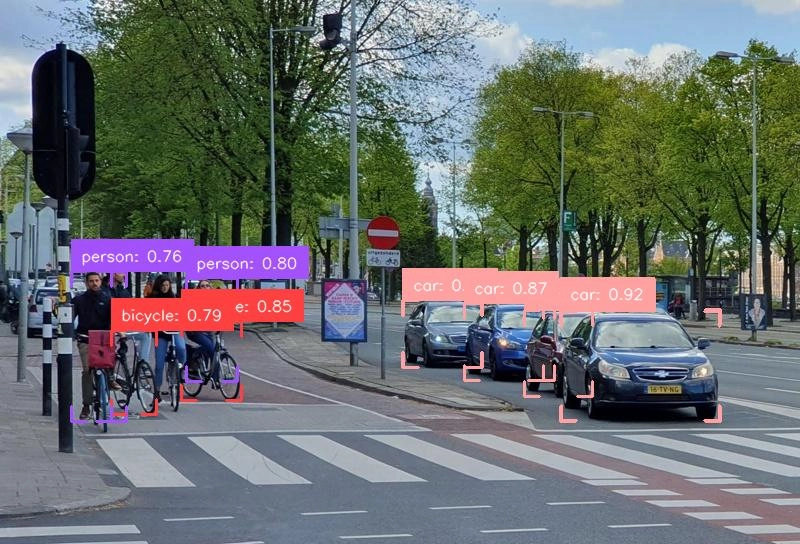

---

### 2-2. 객체 탐지 

> **핵심** 이미지 분류가 "무엇이 있는지"를 맞힌다면, 객체 탐지는 "무엇이 어디에 있는지"까지 함께 예측

객체의 위치는 객체를 둘러싸는 사각형인 **Bounding Box**로 표시하며, 보통 중심 좌표 , 너비 , 높이로 나타냄. 모델은 CNN으로 Feature Map을 얻은 뒤 그 위에 두 개의 head를 올리는 구조다.
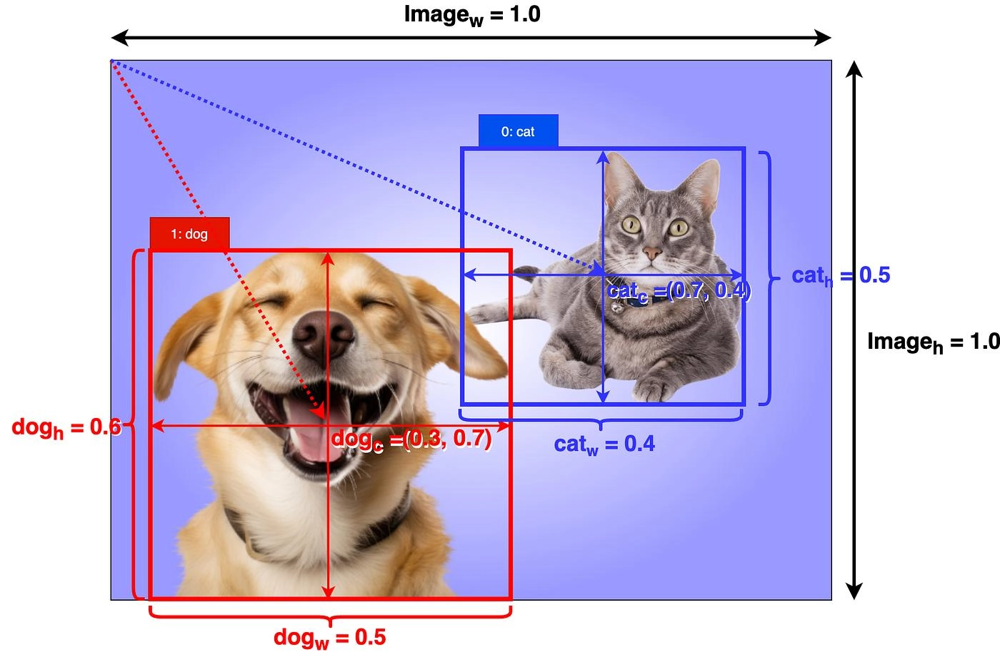
- **Classification Head**: 탐지한 객체가 사람인지, 자동차인지, 강아지인지 종류를 예측함
- **Regression Head**: Bounding Box의 중심 좌표, 너비, 높이를 계산해 위치를 예측함

대표 모델로는 YOLO, Faster R-CNN, SSD가 있음.

---

### 2-3. 이미지 캡셔닝 (Image Captioning)

> **핵심** 이미지 속 객체들의 관계와 행동까지 파악해 자연어 문장으로 표현하는 작업으로 CNN과 RNN을 함께 사용함

캡셔닝은 한 단계 더 나아가 사람, 자전거, 도로를 각각 찾는 것을 넘어 "한 사람이 도로에서 자전거를 타고 있습니다"처럼 관계와 행동을 문장으로 만들어 냄.
- **CNN**은 이미지에서 객체와 시각적 특징을 추출
- **RNN**은 그 특징을 바탕으로, 이전에 만든 단어를 참고해 다음 단어를 예측하며 문장을 완성

진행 단계: CNN으로 특징 추출 → Attention으로 단어 생성 → RNN으로 문장 완성.  **Attention**은 이미지 전체를 똑같이 보지X. 지금 만들려는 단어와 관련된 영역에 더 높은 가중치를 주는 방식임. '사람'을 쓸 때는 사람 영역에, '자전거'를 쓸 때는 자전거 영역에 더 집중하는 식임.
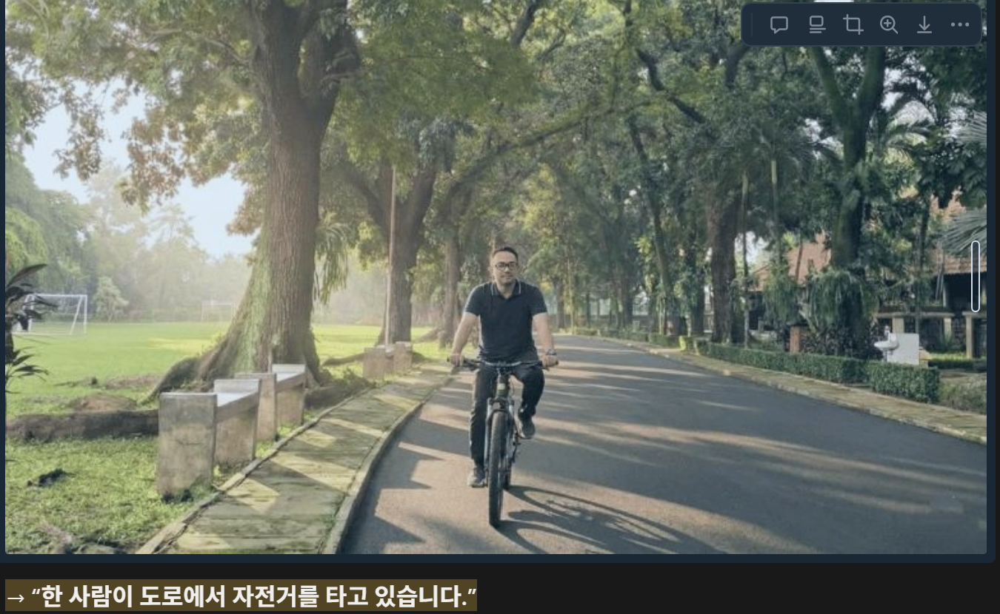


---

## 3. 과거를 기억하는 신경망 RNN!

### 3-1. 순차 데이터

> **핵심** 순서가 의미를 가지는 데이터로, 순서를 바꾸면 정보가 달라지기 때문에 기존 머신러닝과는 다른 모델이 필요함

### 3-1. 순차(Sequence) 데이터

> **핵심** 순서 자체가 의미를 가져서, 순서를 바꾸면 정보가 달라지는 데이터임

**순차 데이터의 분류**

| 분류 기준 | 유형 | 의미 | 예시 |
| --- | --- | --- | --- |
| 순서의 기준 | 시간적 순차 데이터 | 시간 순서로 나열됨 | 주가, 기온 |
| 순서의 기준 | 비시간적 순차 데이터 | 위치·순번 등 시간 외 기준으로 나열됨 | 문장 속 단어, DNA 염기서열 |
| 자료형 | 수치형 | 값의 크기와 거리에 의미가 있음 | 음성, 비디오 |
| 자료형 | 범주형 | 값의 크기와 거리에 의미가 없음 | 웹 클릭 로그, 구매 이력 |

**음성과 비디오가 수치형 순차 데이터인 이유?**

| 구분 | 음성 (Audio) | 비디오 (Video) |
| --- | --- | --- |
| 데이터의 정체 | 시간에 따라 계속 변하는 공기의 진동 | 이미지(프레임)를 빠르게 연속으로 넘긴 것 |
| 숫자로 바뀌는 방식 | 아주 짧은 간격으로 잘라 진폭 값을 정수·실수로 기록 | 각 프레임을 이루는 픽셀 값이 수치 |
| 예시 | 16kHz = 1초에 진폭 값 16,000번 기록 | 30프레임 = 1초에 30장 넘김 |
| 순서가 섞이면 | 전혀 다른 데이터가 됨 | 의미가 완전히 달라짐 |


**정형 데이터 vs 순차 데이터**

| 비교 관점 | 정형 데이터 | 순차 데이터 |
| --- | --- | --- |
| 순서를 섞으면 | 의미가 그대로임 | 의미가 달라짐 → **순서 의존성** |
| 샘플 간 관계 | 서로 독립적 | 이전 시점·순번이 현재에 영향을 줌 → **자기상관성** |
| 대표 데이터 | 고객 정보 | 주가, 문장 |
| 예시 | 고객 A, B, C를 C, A, B로 바꿔도 의미 변화 없음 | "개가 사람을 물었다" ↔ "사람이 개를 물었다"는 완전히 다른 의미 |



---

### 3-2. RNN의 구조와 원리

> **핵심** 은닉층에 순환 구조가 있어서, 매 시점 현재 입력과 이전 은닉 상태를 함께 받아 새 은닉 상태를 만들고 이를 다음 시점으로 넘김

**구조**
기존 신경망과 가장 다른 점은 은닉층의 **순환 구조**임. 구성 요소는 다음과 같음.
- 입력층은 시점 t의 입력 xₜ 
은닉층은 xₜ와 이전 은닉 상태 hₜ₋₁을 함께 받아 새 은닉 상태 hₜ를 만듦 
출력층은 hₜ로 시점 t의 결과 oₜ를 내보냄
- 가중치는 입력을 은닉층으로 보내는 **입력 가중치(U)**, 
이전 은닉 상태를 현재 은닉층으로 보내는 **순환 가중치(V)**
은닉 상태를 출력으로 바꾸는 **출력 가중치(W)** 가 있다
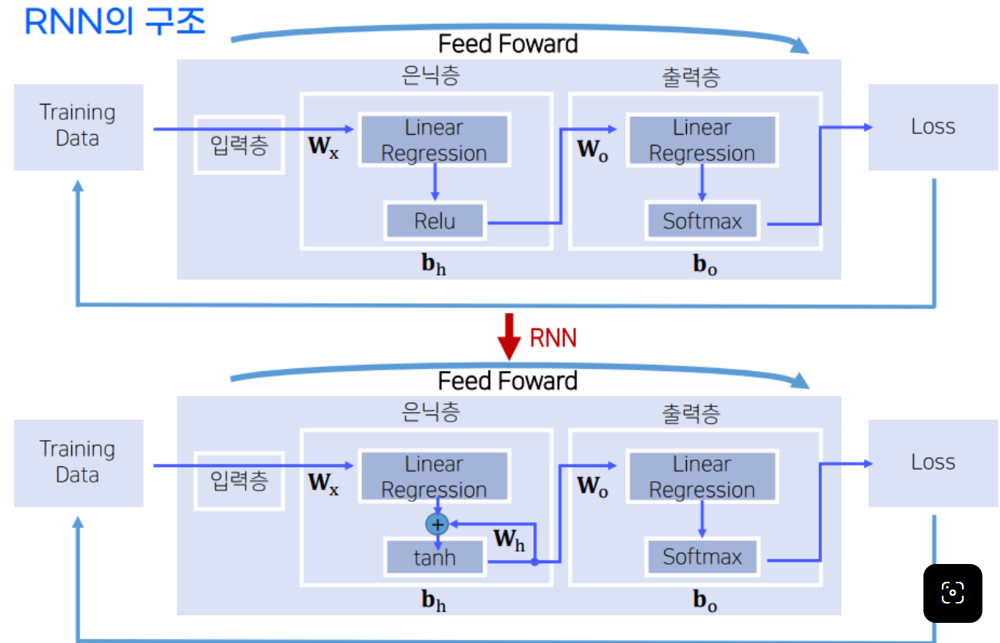

**원리**
은닉 상태는 현재 입력과 이전 은닉 상태에 편향 b를 더해 tanh를 거쳐 계산함. tanh는 값을 -1~1로 제한해 은닉 상태가 폭주하는 것을 막고 비선형성을 더해 복잡한 패턴을 학습할 수 있게 함.

$$
\tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}
$$

이진 분류: 0~1로 압축하는 시그모이드 
다중 분류: 각 점수를 지수로 바꿔 전체 합으로 나눠 합이 1인 확률로 만드는 소프트맥스를 씀.

"나는 / 밥을 / 먹었다" -> t=1에서 "나는"을 처리해 은닉 상태로 넘기고 t=2에서 "나는"과 "밥을"의 정보가 함께 저장되며 t=3에서 문장 전체 맥락이 h₃에 요약되어 활성화 함수를 거쳐 최종 출력이 됨.

**RNN 아키텍처**
입력과 출력의 형태에 따라 세 가지로 나뉨. 여기서 시퀀스는 순서가 있는 데이터의 나열을 말함.
- **One to Many**: 입력 하나로 시퀀스를 출력함. 사진을 첫 시점에 한 번 넣으면 제목을 만들어 내는 이미지 캡셔닝에 쓰임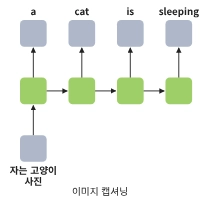
- **Many to One**: 시퀀스를 입력받아 값 하나를 출력함. 문장을 끝까지 읽은 뒤 스팸 여부나 감성(긍정/부정, 또는 기쁨/분노/슬픔/놀람)을 판별하는 데 쓰임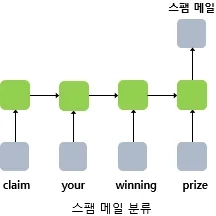
- **Many to Many**: 시퀀스를 입력받아 시퀀스를 출력함. 매 시점 바로 출력하는 동기식은 객체 태깅 등에, 입력을 끝까지 읽은 뒤 한 번에 출력하는 비동기식은 기계 번역이나 요약 등에 쓰임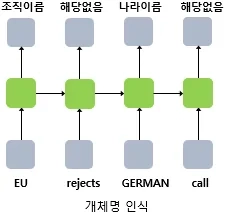

---

### 3-3. RNN의 한계와 장기 의존성 문제

> **핵심** 기울기 소실, 기울기 폭주, 느린 훈련 시간이라는 세 가지 한계는 결국 멀리 떨어진 정보를 기억하지 못하는 장기 의존성 문제로 이어짐

**BPTT 구조**
RNN은 순전파로 시퀀스를 처리한 뒤 **시간을 거슬러 올라가며(BPTT)** 오차를 전파해 기울기를 누적 계산함. 기울기 계산이란 가중치를 살짝 바꿨을 때 오차가 얼마나 변하는지를 재는 것으로, 예를 들어 w를 2에서 2.01로 늘렸더니 오차가 10에서 10.05가 되었다면 기울기는 +5이고, 이는 w를 늘리면 오차가 커진다는 뜻이므로 w를 줄이는 방향(기울기의 반대방향)으로 업데이트함.
이때 chain rule이 쓰인다.

$$
\frac{\partial h_t}{\partial h_{t-1}} = \text{diag}\left(g'(a_t)\right) \times V
$$

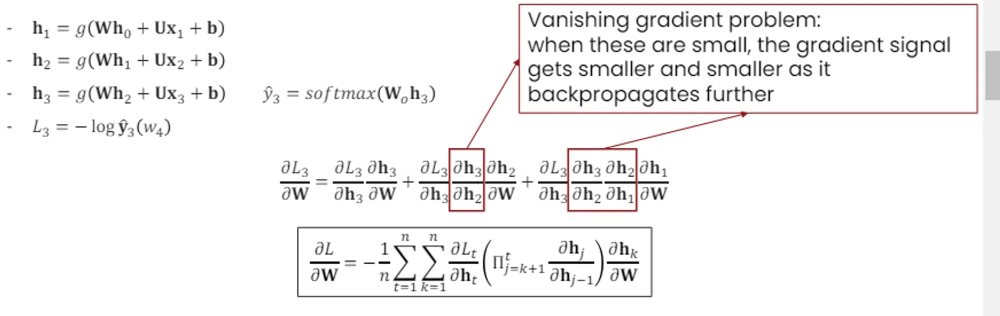

**기울기 소실**
이 곱한 값이 1보다 작으면 과거로 갈수록 기울기가 0에 가까워짐. tanh의 미분값은 최대 1이고 대부분 그보다 작아서, V가 1보다 작으면 반드시 소실되고 조금 커도 소실될 수 있음. 그래서 기본 RNN에서는 폭주보다 소실이 훨씬 자주 일어나며, 결과적으로 가까운 시점은 학습되지만 먼 과거의 정보는 거의 반영X.

**기울기 폭주**
반대로 곱한 값이 1보다 크면 과거로 갈수록 기울기가 매우 커짐. 가중치가 크게 튀면서 오차가 갑자기 치솟거나 진동하게 되는데, 진동은 오차가 10 → 4 → 12 → 3처럼 오르락내리락하는 것을 말함. 심하면 오차가 너무 커져 NaN이 발생하고 학습이 멈춤. 시퀀스가 길수록 학습이 불안정해져 먼 의존 관계를 안정적으로 배우기 어려움.

**느린 훈련 시간**
RNN은 앞 시점의 결과가 있어야 다음을 계산할 수 있어서 시점을 하나씩 순서대로만 처리할 수 있음. 그래서 시퀀스 길이에 비례해 계산 시간이 늘고 역전파를 위해 모든 시점의 은닉 상태를 저장해야 해서 메모리 부담도 큼. 필터가 각 위치를 독립적으로 계산해 병렬 처리가 가능한 CNN과 대비되는 부분임.

**장기 의존성 문제**
세 가지 한계는 모두 먼 과거 정보가 반영되지 않거나, 먼 관계를 안정적으로 배우지 못하거나 배우는 데 비용이 너무 많이 든다는 결과로 이어짐. 결국 **관련 정보가 멀리 떨어져 있을수록 그 관계를 기억하고 학습하지 못하는 장기 의존성 문제**로 귀결됨. 이를 해결하려면 중요한 정보는 오래 기억하고 불필요한 정보는 잊는 메모리 구조가 필요한데 ***그것이 LSTM과 GRU임***

---

## 4. 똑똑하게 기억하고 잊을때는? -> LSTM & GRU

### 4-1. LSTM과 GRU 

> **핵심** 두 모델 모두 게이트로 무엇을 기억하고 무엇을 잊을지 정하며, LSTM은 기억을 둘로 나눠 관리하고 GRU는 하나로 합쳐 관리

**게이트**는 정보를 얼마나 통과시킬지 정하는 장치. 0~1 사이 값을 정보에 곱함. 0이면 버리고, 1이면 그대로 두고, 0.5면 절반만 남김. EX. [5, 3, 8]에 [1, 0, 0.5]를 칸별로 곱하면 [5, 0, 4]가 됨. 이값은 모델이 sigmoid로 스스로 계산하니까 정보를 선택적으로 기억하고 지울 수 있게 되는 것임

**LSTM**은 장기 기억을 담당하는 **셀 상태** 와 단기 기억이자 출력을 담당하는 **은닉 상태** 를 나눠 관리함. 기존 RNN이 h 하나에 모든 걸 덮어썼다면 LSTM은 오래 남길 기억을 따로 빼 둔 것임. 게이트는 세 개로, 필요 없어진 장기 기억을 지우는 **Forget Gate** 새 정보 중 중요한 것만 장기 기억에 저장하는 **Input Gate**, 장기 기억 중 지금 필요한 부분만 단기 기억으로 내보내는 **Output Gate**가 있다. 기억을 분리해 정교하게 다룰 수 O BUT 게이트 3개와 상태 2개로 구조가 복잡하고 계산량이 많음.

**GRU**는 셀 상태와 은닉 상태를 나누지 않고 **은닉 상태  하나**에 기억과 출력을 모두 담음. 게이트는 두 개->
 과거 기억과 새 정보를 몇 대 몇으로 섞을지 정하는 **Update Gate**와 새 정보를 해석할 때 과거 기억을 얼마나 무시할지 정하는 **Reset Gate**가 있음. LSTM보다 단순하고 빠르지만  BUT 기억을 세밀하게 나누지 않아 정교함은 상대적으로 떨어짐.

---

### 4-2. LSTM 정보의 흐름을 제어

> **핵심** 셀 상태가 시점을 따라 덧셈으로 이어지기 때문에 기울기가 먼 과거까지 전달되어 기울기 소실이 완화됨

**구조**
셀 상태는 구조도 맨 위를 가로지르며 시점을 따라 쭉 이어지는 선. 정보가 큰 변화 없이 다음 시점으로 흘러감. 게이트가 여기서 정보를 빼거나(잊기) 더해서(기억) 조절하므로 중요한 정보를 오래 가져갈 수 있음. RNN과 비교하면, RNN은 은닉 상태 하나가 기억과 출력을 모두 맡고 매 시점 통째로 덮어쓰지만 LSTM은 셀 상태와 은닉 상태 두 개가 순환하며 게이트로 선택적으로 지우고 더함.
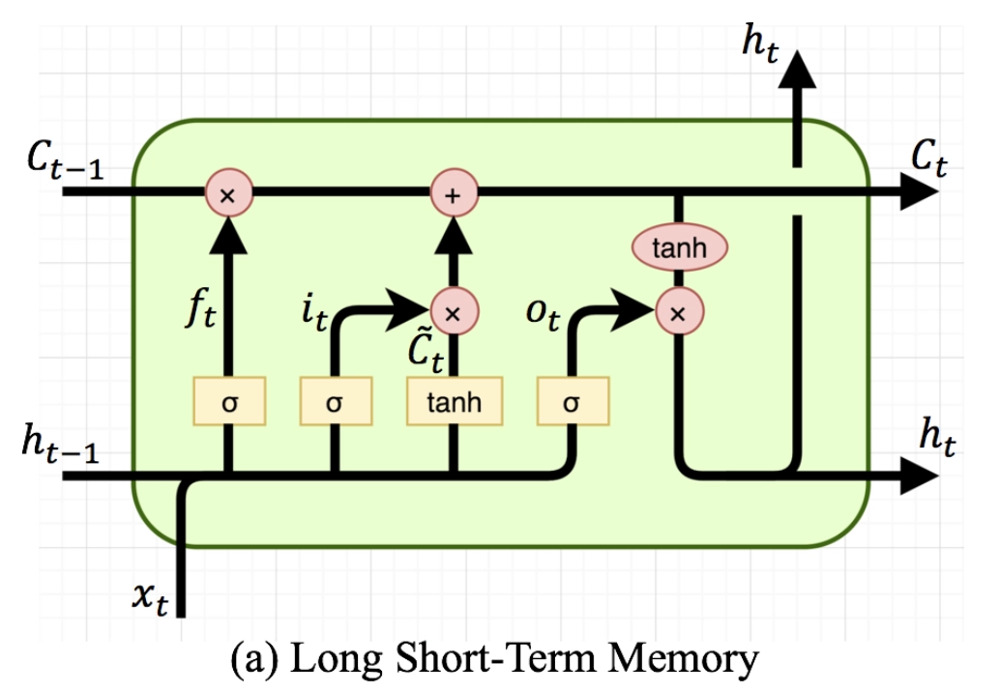

- **Step 1. Forget gate (뭘잊지?)**: 이전 셀 상태 Cₜ₋₁의 각 칸에 곱할 0~1 값 fₜ를 구함. 1에 가까우면 그대로 유지하고, 0에 가까우면 완전히 잊음
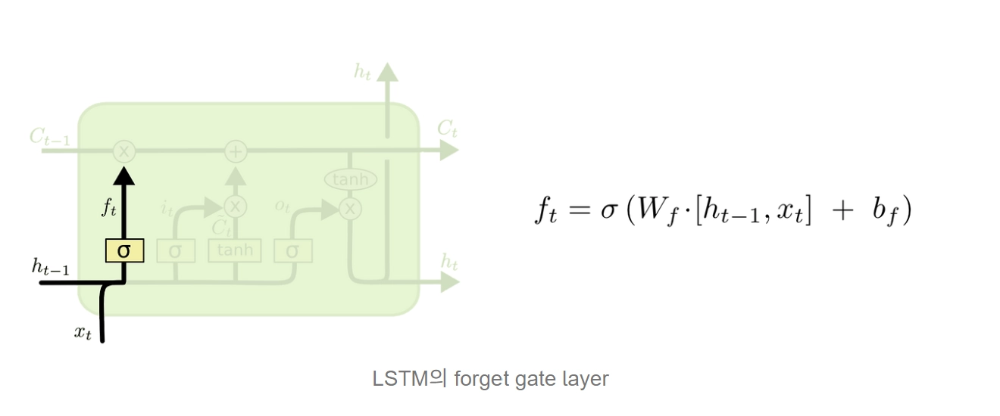
- **Step 2. Input gate (뭘새로기억하지?)**: 새 정보를 얼마나 반영할지 정하는 iₜ와, 이번 시점에 새로 기억할 수도 있는 후보 정보 C̃ₜ를 구함. 실제로 더해지는 양은 iₜ ⊙ C̃ₜ임
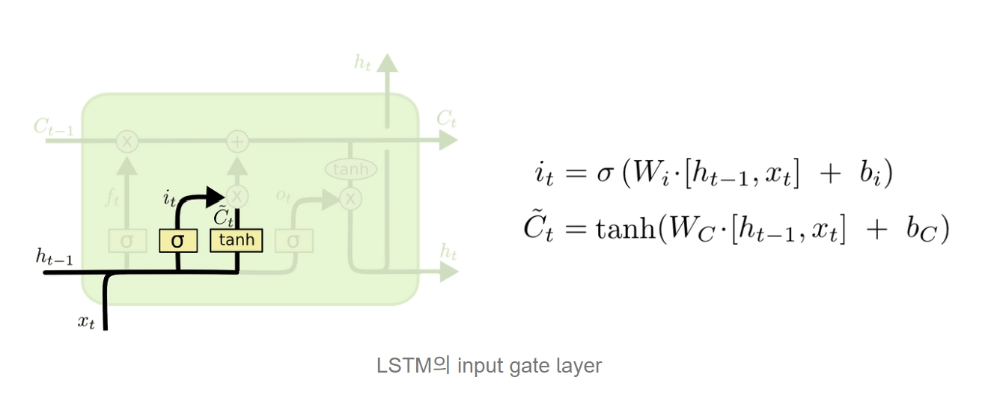


- **Step 3. 기억 업데이트**: Step 1에서 남긴 이전 기억에 Step 2에서 고른 새 정보를 더함. 곱셈X **덧셈으로 이어진다는 점**이 핵심
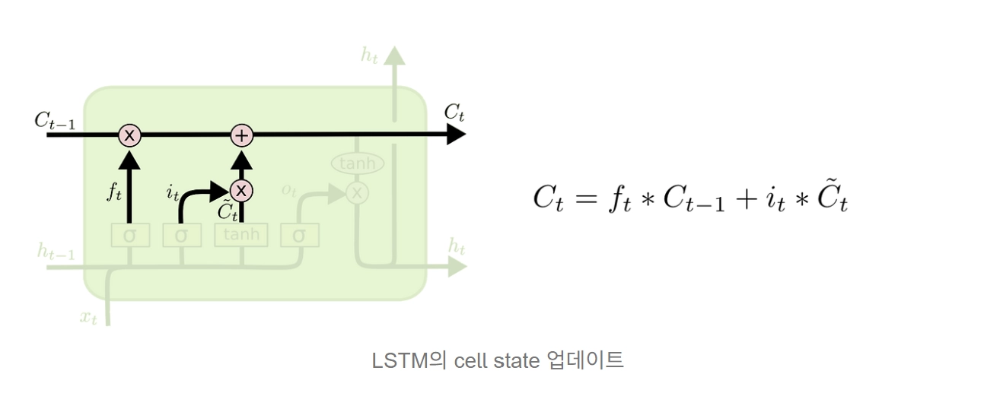

- **Step 4. Output gate (뭘내보내지?)**: 셀 상태 중 어느 부분을 내보낼지 정하고, 셀 상태를 tanh로 -1~1로 정리한 뒤 필요한 부분만 출력
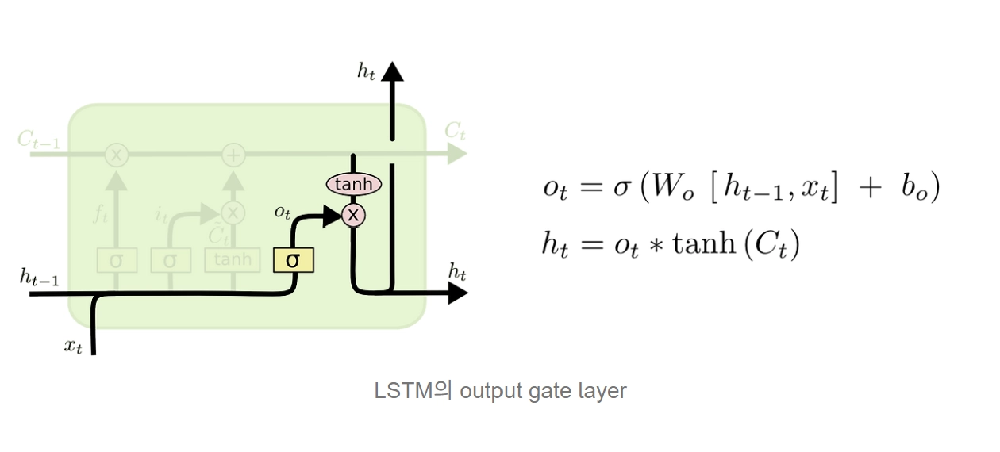

**LSTM의 장단점**

| 구분 | 특징 | 결과 |
| --- | --- | --- |
| 장점 | 셀 상태가 덧셈 구조로 이어져 기울기가 먼 과거까지 전달됨 | 기울기 소실이 완화됨 |
| 장점 | 게이트로 중요한 정보는 남기고 불필요한 정보는 지움 | 장기 의존성 학습이 가능함 |
| 장점 | 긴 시퀀스를 안정적으로 다룸 | 문장 번역, 음성 인식 등에서 RNN보다 성능이 좋음 |
| 단점 | 게이트와 상태가 많아 계산량이 많음 | 학습이 느리고 메모리를 많이 씀 |
| 단점 | 여전히 시점을 순서대로 계산해야 함 | 병렬 처리가 불가능해 느린 훈련 시간 문제가 그대로 남음 |
| 단점 | 기울기 소실을 없앤 게 아니라 완화한 것임 | 매우 긴 시퀀스에서는 여전히 한계가 있음 |

→ 이런 단점 때문에 더 단순한 구조인 **GRU**가 등장!
---

### 4-3. GRU 더 단순하고 효율적인 구조

> **핵심** LSTM의 게이트 아이디어는 유지하면서 상태를 1개 게이트를 2개로 줄여 가볍게 만든 모델임

GRU는 LSTM보다 17년 늦게 나옴. LSTM과의 차이는 네 가지임.

1. **Forget gate와 Input gate를 Update gate 하나로 통합.** zₜ 하나로 과거 기억과 새 정보의 비율을 한 번에 정하고 zₜ가 0.3이면 과거 기억 70%에 새 정보 30%를 섞음
2. **Reset gate를 사용** rₜ로 과거 기억을 얼마나 무시할지 먼저 정한 뒤 후보 정보 h̃ₜ를 만듦. rₜ가 0에 가까우면 과거를 거의 무시하고 현재 입력 위주로 새 정보를 만드는데 문장이 끝나고 새 문장이 시작될 때 이전 문맥을 끊는 경우가 그 예임
3. **Output gate가 없음.** 출력을 거르는 단계 없이 은닉 상태를 그대로 출력함
4. **게이트가 3개에서 2개로 줄어듬.** 파라미터가 LSTM의 약 3/4이라 학습 시간이 짧아지지만 성능은 LSTM과 비슷하거나 과제에 따라 더 좋기도 함

**GRU장단점 (VS LSTM )**

| 구분 | 장점 (LSTM 대비) | 단점 (LSTM 대비) |
| --- | --- | --- |
| 구조 | 상태 1개, 게이트 2개로 단순 → 이해·구현이 쉬움 | 장기 기억과 출력을 분리하지 못함 |
| 속도 | 파라미터가 적어 학습이 빠르고 메모리 사용이 적음 | ❎ |
| 데이터 | 파라미터가 적어 데이터가 적을 때도 학습이 안정적 | 데이터가 많고 복잡한 과제에서는 LSTM이 더 나을 수 있음 |
| 기억 관리 | Update gate 하나로 기억 갱신을 간단히 처리 | 잊는 양과 더하는 양을 따로 조절할 수 없어 정교함이 떨어짐 |
| 성능 | 많은 과제에서 LSTM과 비슷한 성능 | 항상 LSTM보다 낫다고 단정할 수는 없음 |

→ GRU는 **효율** LSTM은 **정교함** 쪽에 강점이 있다

---

### 4-4. LSTM vs GRU 선택?

> **핵심** 두 모델은 우열 관계가 아니라 정교함(LSTM)과 효율(GRU) 사이의 선택이며, 문제 상황에 따라 적합한 모델이 다름

실제 비교 연구에서도 많은 과제에서 두 모델의 성능은 비슷하게 나타남. 따라서 어느 한쪽이 정답은 아님. 풀려는 문제의 특성에 맞춰 고르자

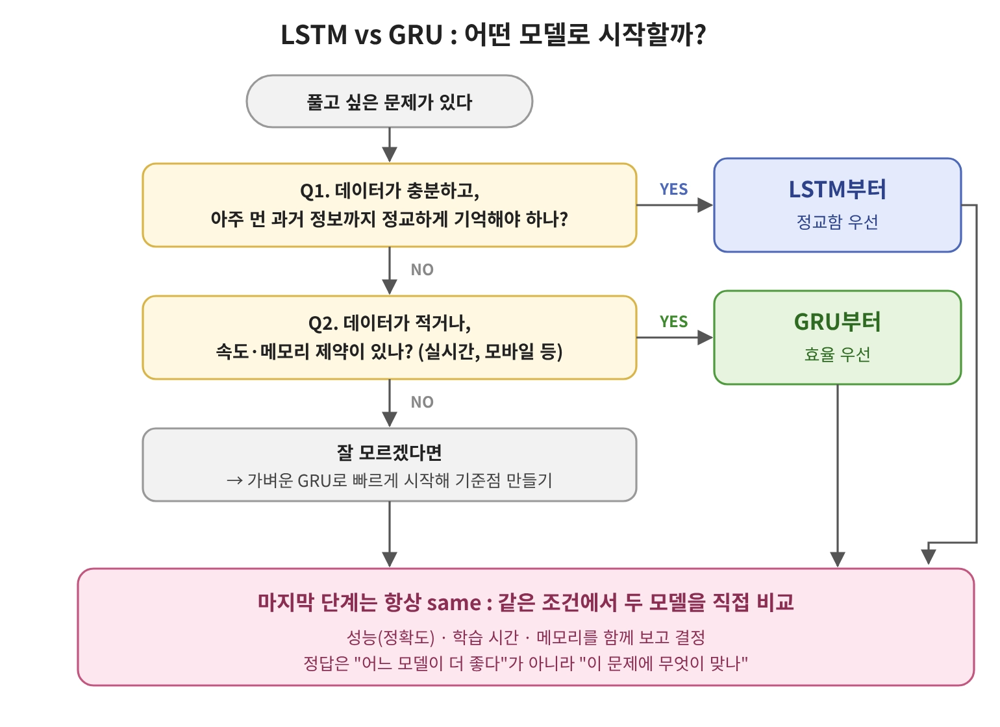

---

## 5. 문장을 입력받아 문장을 출력할때는 Seq2Seq

### 5-1. Seq2Seq의 기본 구조 -> 인코더와 디코더

> **핵심** 인코더가 입력 문장을 읽어 컨텍스트 벡터로 요약하고, 디코더가 그것을 받아 출력 문장을 한 단어씩 써냄

**정의와 특징**
Seq2Seq는 입력 시퀀스를 받아 다른 시퀀스를 출력하는 모델로, **입력과 출력의 길이가 달라도 된다는 점**이 기존 RNN과의 가장 큰 차이.언어마다 어순과 단어 수가 다른 번역 같은 경우에 쓰임. 앞서 본 Many to Many를 두 개의 RNN(LSTM)으로 나눠 구현한 구조이며, 기계 번역, 챗봇, 문서 요약, 음성 인식 등에 활용. 장기 의존성 문제 때문에 내부 셀로는 주로 LSTM이나 GRU를 씀.
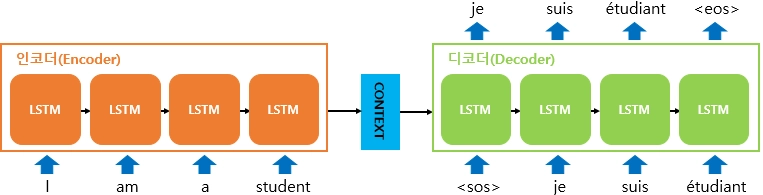

**인코더**
입력 문장의 모든 단어를 순서대로 읽고 문장 전체 정보를 하나의 벡터로 압축하는 LSTM. 먼저 문장을 "I", "am", "a", "student"처럼 단어 단위로 나누고 각 단어를 계산 가능한 숫자 벡터로 바꾼 뒤(임베딩), LSTM 셀에 한 단어씩 넣어 은닉 상태에 정보를 누적. 마지막 시점의 은닉 상태가 문장 전체 정보를 담은 컨텍스트 벡터가 되어 디코더로 전달되며, 중간 시점의 출력은 사용하지 않음.
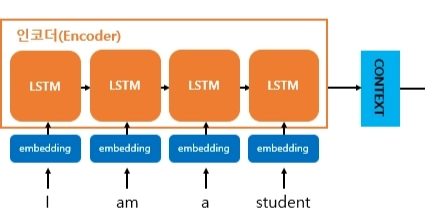

**디코더**
컨텍스트 벡터를 받아 출력 문장을 한 단어씩 생성하는 LSTM임. 컨텍스트 벡터를 첫 은닉 상태로 받고, 시작 신호 `<sos>`를 첫 입력으로 넣은 뒤 매 시점 softmax로 다음 단어의 확률을 계산해 가장 높은 단어를 고름. 방금 예측한 단어는 다시 다음 시점의 입력이 되어 `<sos>` → "je" → "suis" → "étudiant" 순으로 이어지고, 종료 신호 `<eos>`가 나오면 생성을 멈춤.
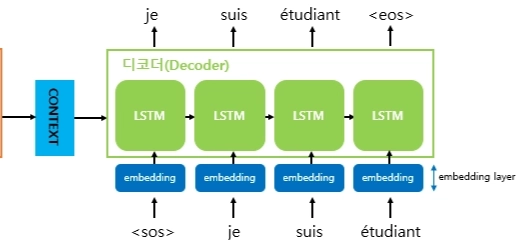

**컨텍스트 벡터**
인코더가 입력 문장 전체를 읽고 만든 문장 요약 벡터로, 인코더 LSTM의 마지막 은닉 상태이며 인코더와 디코더를 잇는 **유일한 통로**임. 크기는 인코더 은닉 상태 크기와 같고 사람이 정하는 하이퍼파라미터로, 보통 256, 512, 1024처럼 수백 차원을 씀. 디코더 은닉 상태 크기도 같은 값으로 맞춰야 바로 이어받을 수 있음. 차원이 크면 더 많은 정보를 담지만 계산량과 과적합 위험이 늘고, 작으면 빠르지만 긴 문장의 정보를 다 담지는X.

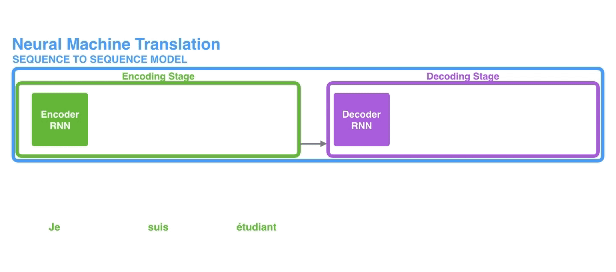
---

### 5-2. Seq2Seq의 한계? -> 병목 현상

> **핵심** 입력 문장 전체를 고정된 크기의 벡터 하나에 압축하기 때문에, 긴 문장일수록 정보가 손실되어 성능이 떨어짐

**병목 현상**은 인코더가 입력 전체를 고정된 크기의 컨텍스트 벡터 하나에 담으면서 정보가 좁은 통로에 막혀 손실되는 현상. 5단어든 50단어든 같은 크기에 담아야 하므로 긴 문장일수록 다 담지 못하고 앞쪽 단어는 여러 시점을 거치며 희미해져 장기 의존성 문제도 여전히 남음.
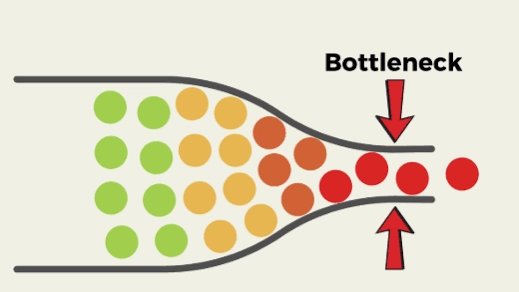

예를 들어 "I am a student"처럼 짧은 문장은 정보가 적어 충분히 담기므로 번역이 정확하지만, "I am a student who moved to Paris last year and …"처럼 수십 단어짜리 문장은 앞부분 정보가 손실되어 주어나 앞 내용을 틀리게 번역하게 됨. 실제 연구에서도 입력 문장이 길어질수록 기본 Seq2Seq의 번역 품질이 급격히 떨어지는 것으로 나타남.
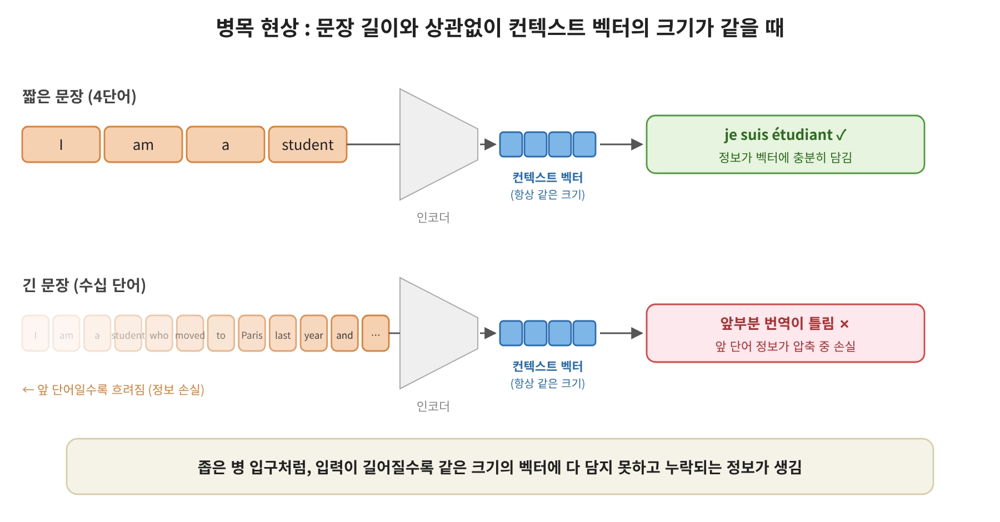

결국! 고정된 크기의 벡터에 모든 정보를 압축하는 구조 때문에 병목이 발생하고 입력이 길수록 정보 손실과 성능 하락이 심해짐. 이 한계를 해결한 것이 다음에 배울 **Attention**이다.